<a href="https://colab.research.google.com/github/devasyapatel-11/BIC-FT3/blob/main/Devasya_Patel_BIC_FT_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Devasya Hitesh Patel                                                    
RA2311003010528                                                       
Problem 17 : Email Spam Detection**

In [90]:

import os
import zipfile
import urllib.request
from io import BytesIO

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    classification_report,
    ConfusionMatrixDisplay
)

import joblib

print("All libraries imported successfully!")


All libraries imported successfully!


Download and load actual email data

In [91]:

url = "https://github.com/MWiechmann/enron_spam_data/raw/refs/heads/master/enron_spam_data.zip"

response = urllib.request.urlopen(url)
zip_bytes = BytesIO(response.read())

with zipfile.ZipFile(zip_bytes) as z:
    csv_files = [
        name for name in z.namelist()
        if name.lower().endswith(".csv")
    ]
    if not csv_files:
        raise FileNotFoundError("No CSV file found in the dataset ZIP.")

    with z.open(csv_files[0]) as f:
        df = pd.read_csv(f)

print("Dataset loaded!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())


Dataset loaded!
Shape: (33716, 5)
Columns: ['Message ID', 'Subject', 'Message', 'Spam/Ham', 'Date']


,Message ID,Subject,Message,Spam/Ham,Date
0,0,christmas tree farm pictures,NaN,ham,1999-12-10
1,1,"vastar resources , inc .","gary , production from the high island larger ...",ham,1999-12-13
2,2,calpine daily gas nomination,- calpine daily gas nomination 1 . doc,ham,1999-12-14
3,3,re : issue,fyi - see note below - already done .\nstella\...,ham,1999-12-14
4,4,meter 7268 nov allocation,fyi .\n- - - - - - - - - - - - - - - - - - - -...,ham,1999-12-14


Clean and prepare the email labels                                          
This cell combines the email subject and body and converts the labels to 1 = Spam and 0 = Legitimate.

In [92]:

df.columns = [str(c).strip().lower() for c in df.columns]

label_col = next(
    (c for c in ["spam/ham", "spam_ham", "label", "class"]
     if c in df.columns),
    None
)

if label_col is None:
    raise ValueError(f"Could not identify the label column: {df.columns.tolist()}")

subject_col = next(
    (c for c in ["subject", "email subject"] if c in df.columns),
    None
)
message_col = next(
    (c for c in ["message", "body", "email", "text"] if c in df.columns),
    None
)

if message_col is None:
    raise ValueError(f"Could not identify the email text column: {df.columns.tolist()}")

subject = df[subject_col].fillna("").astype(str) if subject_col else ""
body = df[message_col].fillna("").astype(str)

df["email_text"] = (subject + " " + body).str.strip()
df["label_text"] = df[label_col].astype(str).str.strip().str.lower()

df = df[df["label_text"].isin(["spam", "ham", "legitimate", "legit"])].copy()
df["label"] = df["label_text"].map({
    "spam": 1,
    "ham": 0,
    "legitimate": 0,
    "legit": 0
})

df = df[df["email_text"].str.len() > 0]
df = df.drop_duplicates(subset=["email_text"]).reset_index(drop=True)

X = df["email_text"]
y = df["label"].astype(int)

print("Total usable emails:", len(df))
print("\nLabel distribution:")
print(y.value_counts().rename(index={0: "Legitimate", 1: "Spam"}))


Total usable emails: 30462

Label distribution:
label
Legitimate    15910
Spam          14552
Name: count, dtype: int64


Visualize the dataset

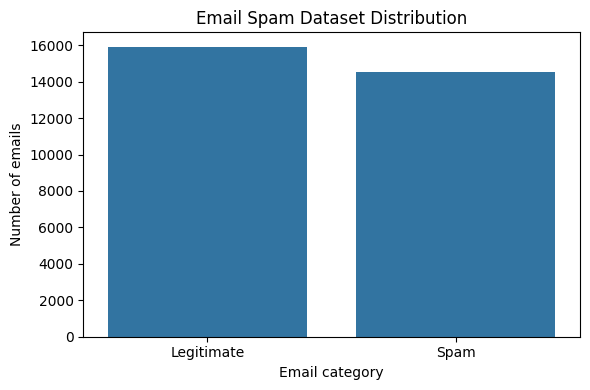

In [93]:

counts = y.value_counts().reindex([0, 1], fill_value=0)

plt.figure(figsize=(6, 4))
sns.barplot(x=["Legitimate", "Spam"], y=counts.values)
plt.title("Email Spam Dataset Distribution")
plt.xlabel("Email category")
plt.ylabel("Number of emails")
plt.tight_layout()
plt.show()


Split the data and extract TF-IDF features                             
We split the data before fitting TF-IDF to avoid data leakage.

In [94]:

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev,
    test_size=0.20,
    random_state=42,
    stratify=y_dev
)

vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),
    max_features=1000,
    sublinear_tf=True
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_val_tfidf = vectorizer.transform(X_val)
X_test_tfidf = vectorizer.transform(X_test)

feature_names = np.array(vectorizer.get_feature_names_out())
NUM_FEATURES = len(feature_names)

print("Training emails:", len(X_train))
print("Validation emails:", len(X_val))
print("Test emails:", len(X_test))
print("TF-IDF features:", NUM_FEATURES)


Training emails: 19495
Validation emails: 4874
Test emails: 6093
TF-IDF features: 1000


Define the Genetic Algorithm fitness function                          
The Genetic Algorithm will choose a subset of TF-IDF features. Its fitness rewards spam detection, with extra emphasis on recall so fewer spam emails are missed, while applying a small penalty for using too many features.

In [95]:

LAMBDA = 0.01
fitness_cache = {}

def evaluate_fitness(chromosome):
    key = chromosome.tobytes()

    if key in fitness_cache:
        return fitness_cache[key]

    selected = np.flatnonzero(chromosome)

    if len(selected) == 0:
        return 0.0

    model = MultinomialNB(alpha=0.5)
    model.fit(X_train_tfidf[:, selected], y_train)

    predictions = model.predict(X_val_tfidf[:, selected])

    spam_f2 = fbeta_score(
        y_val,
        predictions,
        beta=2,
        zero_division=0
    )

    feature_penalty = LAMBDA * (
        len(selected) / len(chromosome)
    )

    fitness = spam_f2 - feature_penalty
    fitness_cache[key] = fitness

    return fitness


Run the Genetic Algorithm

In [96]:

POPULATION_SIZE = 12
GENERATIONS = 10
MUTATION_RATE = 0.03
ELITE_COUNT = 2

rng = np.random.default_rng(42)

population = rng.integers(
    0, 2,
    size=(POPULATION_SIZE, NUM_FEATURES)
)

# Ensure each chromosome selects at least one feature
for chromosome in population:
    if chromosome.sum() == 0:
        chromosome[rng.integers(NUM_FEATURES)] = 1

best_fitness_history = []
mean_fitness_history = []

def tournament_select(population, fitnesses, k=3):
    candidates = rng.choice(
        len(population),
        size=k,
        replace=False
    )
    winner = candidates[np.argmax(fitnesses[candidates])]
    return population[winner].copy()

for generation in range(GENERATIONS):
    fitnesses = np.array([
        evaluate_fitness(chromosome)
        for chromosome in population
    ])

    best_idx = np.argmax(fitnesses)
    best_fitness_history.append(fitnesses[best_idx])
    mean_fitness_history.append(fitnesses.mean())

    print(
        f"Generation {generation + 1}/{GENERATIONS} | "
        f"Best fitness: {fitnesses[best_idx]:.4f}"
    )

    elite_indices = np.argsort(fitnesses)[-ELITE_COUNT:]
    new_population = [
        population[i].copy() for i in elite_indices
    ]

    while len(new_population) < POPULATION_SIZE:
        parent1 = tournament_select(population, fitnesses)
        parent2 = tournament_select(population, fitnesses)

        mask = rng.integers(0, 2, size=NUM_FEATURES)
        child = np.where(mask == 1, parent1, parent2)

        mutation_mask = rng.random(NUM_FEATURES) < MUTATION_RATE
        child[mutation_mask] = 1 - child[mutation_mask]

        if child.sum() == 0:
            child[rng.integers(NUM_FEATURES)] = 1

        new_population.append(child)

    population = np.array(new_population)

# Select the best chromosome from the final population
final_fitnesses = np.array([
    evaluate_fitness(chromosome)
    for chromosome in population
])

best_chromosome = population[np.argmax(final_fitnesses)].copy()
selected_indices = np.flatnonzero(best_chromosome)

print("\nGenetic Algorithm completed!")
print("Selected features:", len(selected_indices))
print("Total features:", NUM_FEATURES)
print(f"Best validation fitness: {final_fitnesses.max():.4f}")


Generation 1/10 | Best fitness: 0.9323
Generation 2/10 | Best fitness: 0.9367
Generation 3/10 | Best fitness: 0.9371
Generation 4/10 | Best fitness: 0.9371
Generation 5/10 | Best fitness: 0.9389
Generation 6/10 | Best fitness: 0.9404
Generation 7/10 | Best fitness: 0.9419
Generation 8/10 | Best fitness: 0.9435
Generation 9/10 | Best fitness: 0.9435
Generation 10/10 | Best fitness: 0.9435

Genetic Algorithm completed!
Selected features: 532
Total features: 1000
Best validation fitness: 0.9435


Plot GA progress and feature selection

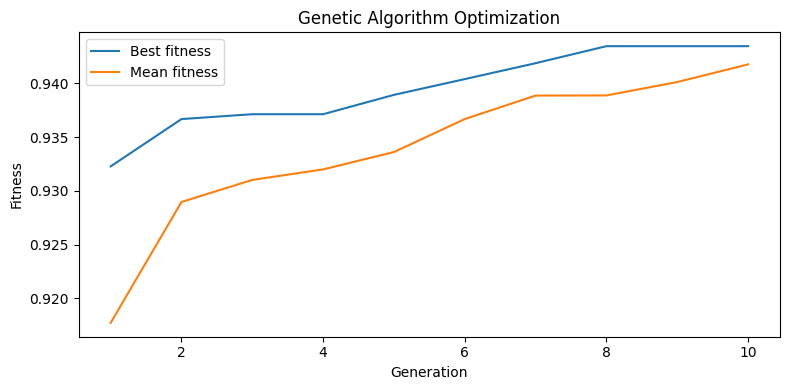

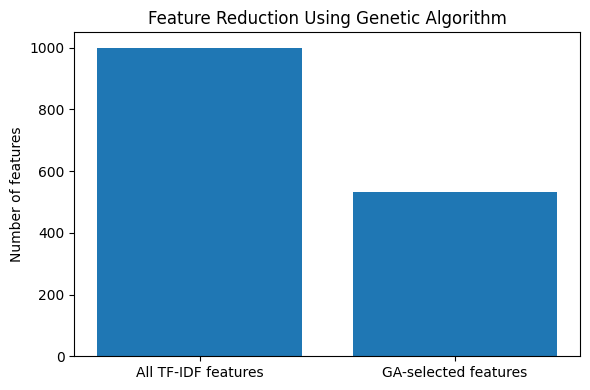

Selected email text features:
['00 00' '000' '01' '02' '03' '04' '05' '09' '100' '13' '17' '19' '20'
 '2000 10' '2001 10' '2001 11' '2004' '2005' '23' '24' '27' '300' '31'
 '32' '33' '35' '36' '39' '42' '48' '52' '55' '57' '59' '69' '70' '713'
 '713 853' '75' '90' '95' '99' 'ability' 'according' 'acquisition' 'act'
 'action' 'add' 'addition' 'address']


In [97]:

plt.figure(figsize=(8, 4))
plt.plot(range(1, GENERATIONS + 1), best_fitness_history, label="Best fitness")
plt.plot(range(1, GENERATIONS + 1), mean_fitness_history, label="Mean fitness")
plt.xlabel("Generation")
plt.ylabel("Fitness")
plt.title("Genetic Algorithm Optimization")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
plt.bar(
    ["All TF-IDF features", "GA-selected features"],
    [NUM_FEATURES, len(selected_indices)]
)
plt.ylabel("Number of features")
plt.title("Feature Reduction Using Genetic Algorithm")
plt.tight_layout()
plt.show()

print("Selected email text features:")
print(feature_names[selected_indices][:50])


Train the final GA model and baseline model                            
The GA model uses only selected features. The baseline uses all TF-IDF features, letting you compare whether feature selection helps.

In [98]:

ga_model = MultinomialNB(alpha=0.5)
ga_model.fit(
    X_train_tfidf[:, selected_indices],
    y_train
)

ga_predictions = ga_model.predict(
    X_test_tfidf[:, selected_indices]
)

baseline_model = MultinomialNB(alpha=0.5)
baseline_model.fit(X_train_tfidf, y_train)
baseline_predictions = baseline_model.predict(X_test_tfidf)

print("GA model and baseline model trained successfully.")


GA model and baseline model trained successfully.


Evaluate the final GA model

===== GA-OPTIMIZED EMAIL SPAM DETECTION =====

Classification report:
              precision    recall  f1-score   support

  Legitimate       0.95      0.96      0.95      3182
        Spam       0.95      0.94      0.95      2911

    accuracy                           0.95      6093
   macro avg       0.95      0.95      0.95      6093
weighted avg       0.95      0.95      0.95      6093

Accuracy: 0.9508
Spam precision: 0.9535
Spam recall: 0.943
Spam F1-score: 0.9482


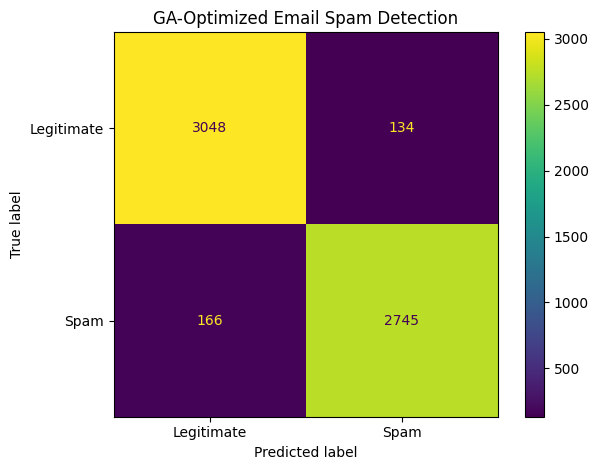

In [99]:

print("===== GA-OPTIMIZED EMAIL SPAM DETECTION =====")

print("\nClassification report:")
print(classification_report(
    y_test,
    ga_predictions,
    labels=[0, 1],
    target_names=["Legitimate", "Spam"],
    zero_division=0
))

print("Accuracy:", round(accuracy_score(y_test, ga_predictions), 4))
print("Spam precision:", round(precision_score(y_test, ga_predictions, zero_division=0), 4))
print("Spam recall:", round(recall_score(y_test, ga_predictions, zero_division=0), 4))
print("Spam F1-score:", round(f1_score(y_test, ga_predictions, zero_division=0), 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    ga_predictions,
    labels=[0, 1],
    display_labels=["Legitimate", "Spam"],
    values_format="d"
)

plt.title("GA-Optimized Email Spam Detection")
plt.tight_layout()
plt.show()


Compare the baseline & GA models

,Model,Accuracy,Spam Precision,Spam Recall,Spam F1
0,Naive Bayes Baseline,0.9649,0.9607,0.966,0.9633
1,GA-Optimized Naive Bayes,0.9508,0.9535,0.943,0.9482


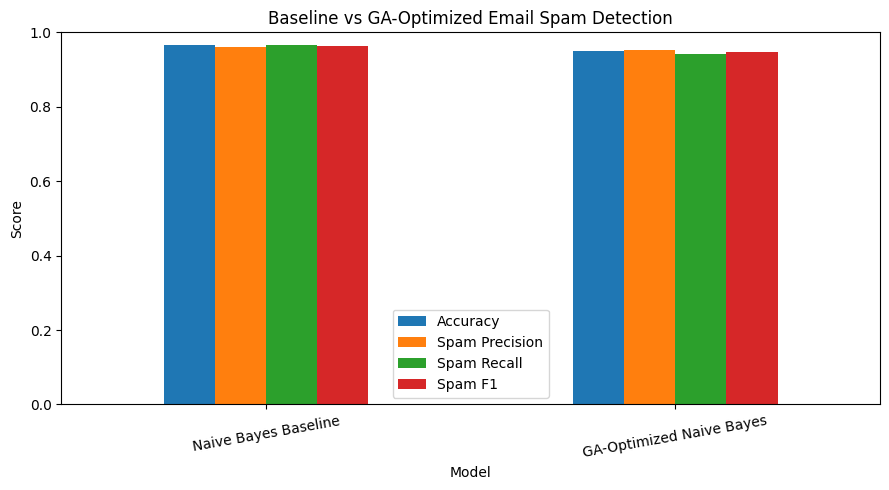

In [100]:

results = pd.DataFrame({
    "Model": ["Naive Bayes Baseline", "GA-Optimized Naive Bayes"],
    "Accuracy": [
        accuracy_score(y_test, baseline_predictions),
        accuracy_score(y_test, ga_predictions)
    ],
    "Spam Precision": [
        precision_score(y_test, baseline_predictions, zero_division=0),
        precision_score(y_test, ga_predictions, zero_division=0)
    ],
    "Spam Recall": [
        recall_score(y_test, baseline_predictions, zero_division=0),
        recall_score(y_test, ga_predictions, zero_division=0)
    ],
    "Spam F1": [
        f1_score(y_test, baseline_predictions, zero_division=0),
        f1_score(y_test, ga_predictions, zero_division=0)
    ]
})

display(results.round(4))

results.set_index("Model").plot(
    kind="bar",
    figsize=(9, 5),
    ylim=(0, 1)
)
plt.title("Baseline vs GA-Optimized Email Spam Detection")
plt.ylabel("Score")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()


Test sample emails

In [101]:

def detect_spam(email_text):
    email_features = vectorizer.transform([email_text])
    selected_features = email_features[:, selected_indices]

    prediction = ga_model.predict(selected_features)[0]
    probabilities = ga_model.predict_proba(selected_features)[0]
    spam_index = list(ga_model.classes_).index(1)
    spam_probability = probabilities[spam_index]

    category = "SPAM" if prediction == 1 else "LEGITIMATE"

    print("Email:", email_text)
    print("Predicted category:", category)
    print(f"Estimated spam probability: {spam_probability:.2%}")
    print("-" * 60)

    return category

test_emails = [
    "Congratulations! You have won a free prize. Click here to claim your reward.",
    "Dear customer, verify your bank account immediately to avoid suspension.",
    "Hi team, please find the meeting agenda attached for tomorrow.",
]

for email in test_emails:
    detect_spam(email)


Email: Congratulations! You have won a free prize. Click here to claim your reward.
Predicted category: SPAM
Estimated spam probability: 94.41%
------------------------------------------------------------
Email: Dear customer, verify your bank account immediately to avoid suspension.
Predicted category: SPAM
Estimated spam probability: 79.90%
------------------------------------------------------------
Email: Hi team, please find the meeting agenda attached for tomorrow.
Predicted category: LEGITIMATE
Estimated spam probability: 7.77%
------------------------------------------------------------


Save your trained model

In [102]:

model_bundle = {
    "vectorizer": vectorizer,
    "selected_indices": selected_indices,
    "model": ga_model,
    "feature_names": feature_names
}

joblib.dump(model_bundle, "email_spam_ga_model.pkl")

print("Model saved as email_spam_ga_model.pkl")


Model saved as email_spam_ga_model.pkl


## Project Conclusion: Email Spam Detection Using a Genetic Algorithm

### Objective
The objective of this project is to classify emails as spam or legitimate using supervised machine learning and to investigate whether a Genetic Algorithm can select a smaller set of useful TF-IDF text features.

### Methodology
The Enron-Spam email dataset is cleaned and labelled, with spam represented by 1 and legitimate email represented by 0. TF-IDF converts the email text into numerical features. A Genetic Algorithm searches for useful feature subsets using population initialization, tournament selection, uniform crossover, bit-flip mutation, and elitism.

The fitness function uses the spam F2-score, which places greater emphasis on recall, and applies a penalty for selecting too many features. A Multinomial Naive Bayes classifier is trained using the selected features.

### Results
The GA-optimized model achieved 95.08% test accuracy, 95.35% spam precision, 94.30% spam recall, and a spam F1-score of 94.82%. It selected 532 out of 1,000 available TF-IDF features, reducing the feature count by 46.8%.

The baseline Naive Bayes model using all features achieved 96.49% accuracy. Therefore, feature selection reduced the number of features but did not improve predictive performance in this experiment.

### Limitations and Future Scope
The Genetic Algorithm was run with a limited population and number of generations. Further experiments could test different fitness penalties, population sizes, mutation rates, and feature-selection strategies. The dataset is historical, so performance on newer spam and phishing emails may differ.

### Conclusion
This project demonstrates the use of supervised learning for email spam detection and a bio-inspired Genetic Algorithm for feature selection. The experiment shows that reducing the feature count does not necessarily improve classification accuracy, highlighting the trade-off between model simplicity and predictive performance.